# Homework 2
## Event Detection and Voice Activity Detection on the VOiCES Dataset

**Student name:** Haneen fuad alkadhimi  
**Student ID:** 404131081

---

## 1. Introduction
In this homework I used the VOiCES dataset to work on two audio tasks. The first task is event detection, where the goal is to find which type of background noise is present in a recording. The second task is voice activity detection (VAD), where the goal is to decide for every short frame of audio whether it contains speech or not.

For both tasks I first tried simple methods and then trained deep learning models in PyTorch and torchaudio. All experiments were run in Google Colab with a T4 GPU.

# Part A – Event Detection (none / babb / musi / tele)

## 2. Dataset
VOiCES (Voices Obscured in Complex Environmental Settings) was recorded by SRI International and Lab41. Clean read speech from LibriSpeech was played through a loudspeaker inside real rooms and recorded with several microphones, while background noise was played at the same time.

Because the full dataset is very large, I used the smaller subset recommended by the instructor (github.com/Lab41/VOiCES-subset). It contains recordings where the speaker is at 90 degrees. After extracting the files I had:
- 908 audio files with an average length of about 15.6 seconds.
- 4 noise types: none (227 files), babble (228), music (231) and TV (222). The classes are well balanced.
- 2 rooms (rm1 and rm2) and 4 microphone positions (close, mid, far and behind).
- 104 different speakers.

All labels (room, noise type, speaker and microphone) were read directly from the file names, for example: `Lab41-SRI-VOiCES-rm1-babb-sp0093-ch126208-sg0004-mc05-stu-far-dg090.wav`.

In [1]:
!pip install -q silero-vad
import os, glob
import numpy as np, pandas as pd

if not os.path.exists('/content/VOiCES-subset'):
    !git clone https://github.com/Lab41/VOiCES-subset /content/VOiCES-subset
%cd /content/VOiCES-subset

if len(glob.glob('data/**/*.wav', recursive=True)) == 0:
    !mkdir -p data
    !for f in VOiCES_90_*.tar; do tar -xf "$f" -C data; done

files = sorted(glob.glob('data/**/*.wav', recursive=True))

def parse(p):
    t = os.path.basename(p)[:-4].split('-')
    return dict(path=p, room=t[3], noise=t[4], speaker=t[5])

meta = pd.DataFrame([parse(p) for p in files])
print(len(meta), 'files')
print(meta.noise.value_counts())
print(meta.room.value_counts())
print('speakers:', meta.speaker.nunique())
print(os.path.basename(files[0]))

Cloning into '/content/VOiCES-subset'...
remote: Enumerating objects: 43, done.
remote: Total 43 (delta 0), reused 0 (delta 0), pack-reused 43 (from 1)
Receiving objects: 100% (43/43), 365.23 MiB | 29.02 MiB/s, done.
Resolving deltas: 100% (8/8), done.
Updating files: 100% (22/22), done.
/content/VOiCES-subset
tar: Removing leading `/' from member names
908 files
noise
musi    231
babb    228
none    227
tele    222
Name: count, dtype: int64
room
rm2    462
rm1    446
Name: count, dtype: int64
speakers: 104
Lab41-SRI-VOiCES-rm1-babb-sp0093-ch126208-sg0004-mc05-stu-far-dg090.wav


## 3. Data Preparation
Every file was loaded at 16 kHz. From each file I computed:
- A log-Mel spectrogram with 64 Mel bands and a hop of 10 ms. This is the input for both deep models.
- 40 MFCCs and their deltas. I took the mean and standard deviation over time, giving 160 numbers per file for the classical classifiers.
- The frame energy in dB, used by the energy-based VAD baseline.

The data was split into training and test sets by speaker, so the same speaker never appears in both sets. This avoids data leakage and gives a fairer test. The result was 652 training files and 256 test files, and the four noise classes stayed balanced in the test set (62 to 67 files each).

In [2]:
import torch, torchaudio, soundfile as sf
from sklearn.model_selection import GroupShuffleSplit

SR, HOP = 16000, 160   # كل frame = 10ms
meta['mic_loc'] = [os.path.basename(p).split('-')[10] for p in meta.path]

melT  = torchaudio.transforms.MelSpectrogram(SR, n_fft=400, hop_length=HOP, n_mels=64)
mfccT = torchaudio.transforms.MFCC(SR, n_mfcc=40,
          melkwargs=dict(n_fft=400, hop_length=HOP, n_mels=64))

wavs, mels, energy, mfcc_feats = [], [], [], []
for p in meta.path:
    x, sr = sf.read(p, dtype='float32')
    if x.ndim > 1: x = x.mean(1)
    x = torch.from_numpy(x)
    if sr != SR: x = torchaudio.functional.resample(x, sr, SR)
    wavs.append(x)
    m = melT(x)
    mels.append(torch.log(m + 1e-6))
    energy.append(10 * torch.log10(m.sum(0) + 1e-10))
    c = mfccT(x); dc = torchaudio.functional.compute_deltas(c)
    mfcc_feats.append(torch.cat([c.mean(1), c.std(1), dc.mean(1), dc.std(1)]).numpy())

meta['dur'] = [len(w) / SR for w in wavs]
print(meta.dur.describe())
print(meta.mic_loc.value_counts())

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0)
tr_idx, te_idx = next(gss.split(meta, groups=meta.speaker))
print('train:', len(tr_idx), ' test:', len(te_idx))
print(meta.iloc[te_idx].noise.value_counts())

count    908.000000
mean      15.560374
std        2.055387
min        2.660000
25%       15.565000
50%       15.985000
75%       16.370000
max       19.100000
Name: dur, dtype: float64
mic_loc
clo    251
beh    227
far    219
mid    211
Name: count, dtype: int64
train: 652  test: 256
noise
musi    67
none    64
babb    63
tele    62
Name: count, dtype: int64


## 4. Part A: Event Detection
The goal here is to recognise the background noise type (none, babble, music or TV) in each recording.

### 4.1 Classical classifiers on MFCC features
I trained six classifiers from scikit-learn on the 160 MFCC statistics. The features were standardised before training. The results on the test set are shown in Table 1.

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

le = LabelEncoder().fit(meta.noise)
y = le.transform(meta.noise); CLASSES = list(le.classes_)
X = np.stack(mfcc_feats)

clfs = {
    'LogReg':       LogisticRegression(max_iter=3000),
    'SVM-RBF':      SVC(C=10, gamma='scale'),
    'kNN':          KNeighborsClassifier(5),
    'RandomForest': RandomForestClassifier(300, random_state=0),
    'GradBoost':    GradientBoostingClassifier(random_state=0),
    'MLP':          MLPClassifier((256, 128), max_iter=1000, random_state=0),
}
res_A = []
for n, c in clfs.items():
    pr = make_pipeline(StandardScaler(), c).fit(X[tr_idx], y[tr_idx]).predict(X[te_idx])
    acc = accuracy_score(y[te_idx], pr); f1 = f1_score(y[te_idx], pr, average='macro')
    res_A.append((n, acc, f1))
    print(f'{n:13s} acc={acc:.3f}  macroF1={f1:.3f}')

LogReg        acc=0.785  macroF1=0.785
SVM-RBF       acc=0.820  macroF1=0.816
kNN           acc=0.598  macroF1=0.572
RandomForest  acc=0.766  macroF1=0.752
GradBoost     acc=0.738  macroF1=0.733
MLP           acc=0.770  macroF1=0.767


**Table 1. Event detection results with classical classifiers**

| Model | Accuracy | Macro F1 |
|---|:---:|:---:|
| Logistic Regression | 0.785 | 0.785 |
| SVM (RBF) | 0.820 | 0.816 |
| k-NN (k=5) | 0.598 | 0.572 |
| Random Forest | 0.766 | 0.752 |
| Gradient Boosting | 0.738 | 0.733 |
| MLP | 0.770 | 0.767 |

SVM gave the best result with 82% accuracy. k-NN was the weakest at about 60%. Since there are four balanced classes, random guessing would give only 25%, so all models learned useful information. The main limit here is that taking the mean and standard deviation over the whole file loses the time information in the sound.

### 4.2 CNN on log-Mel spectrograms
Next I trained a convolutional neural network (CNN) directly on the log-Mel spectrogram. The network has four convolution blocks (convolution, batch normalisation, ReLU and max pooling) followed by global average pooling and a linear layer with four outputs.
- **Training:** random 3-second crops were taken from each file. SpecAugment (frequency and time masking) was used to reduce overfitting. The model was trained for 40 epochs with AdamW and a One-Cycle learning rate schedule. The training loss went down from 1.02 to about 0.44.
- **Detection over time:** at test time a 3-second window slides over the file with a step of 1 second. The model gives the probability of each noise type for every window, so we can see the detected event over time. The final label of the file is the class with the highest average probability.

cuda
epoch 5  loss 1.019
epoch 10  loss 0.818
epoch 15  loss 0.720
epoch 20  loss 0.612
epoch 25  loss 0.523
epoch 30  loss 0.456
epoch 35  loss 0.396
epoch 40  loss 0.443
CNN acc=0.949  macroF1=0.948
              precision    recall  f1-score   support

        babb       0.94      1.00      0.97        63
        musi       0.98      0.94      0.96        67
        none       0.94      0.97      0.95        64
        tele       0.93      0.89      0.91        62

    accuracy                           0.95       256
   macro avg       0.95      0.95      0.95       256
weighted avg       0.95      0.95      0.95       256



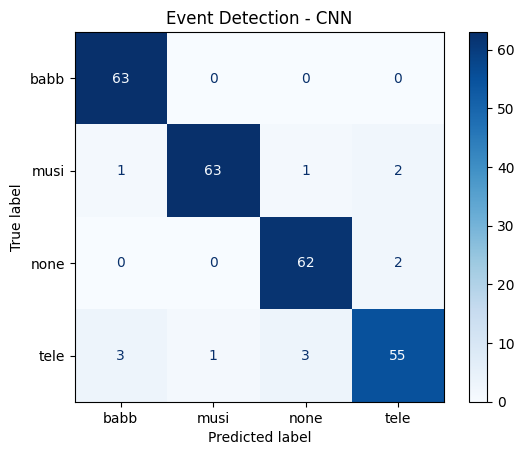

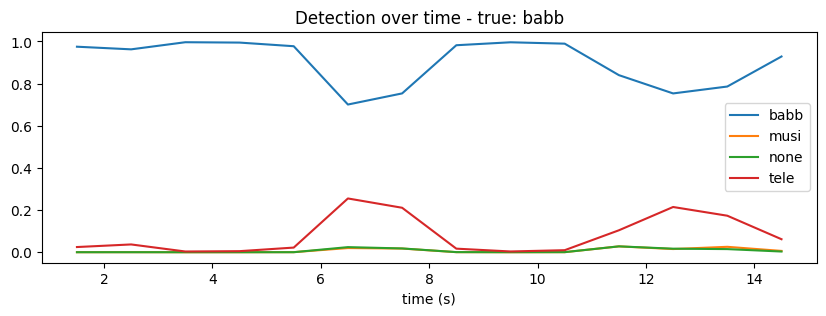

In [4]:
import random, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
dev = 'cuda' if torch.cuda.is_available() else 'cpu'; print(dev)
torch.manual_seed(0); random.seed(0)

# Normalization stats from training set
allm = torch.cat([mels[i] for i in tr_idx], 1)
MU, SD = allm.mean().item(), allm.std().item()
norm = lambda m: (m - MU) / SD
WIN = 300   # 3-second window (300 frames x 10 ms)

# Dataset: random 3 s crop from each file
class ClipDS(torch.utils.data.Dataset):
    def __init__(s, idx): s.idx = idx
    def __len__(s): return len(s.idx)
    def __getitem__(s, k):
        i = s.idx[k]; m = norm(mels[i])
        if m.shape[1] < WIN: m = F.pad(m, (0, WIN - m.shape[1]))
        st = random.randint(0, m.shape[1] - WIN)
        return m[:, st:st+WIN].unsqueeze(0), y[i]

# CNN model
def blk(i, o, pool=(2, 2)):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(pool))

class EventCNN(nn.Module):
    def __init__(s, n):
        super().__init__()
        s.f = nn.Sequential(blk(1,32), blk(32,64), blk(64,128), blk(128,128))
        s.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(128, n))
    def forward(s, x): return s.head(s.f(x).mean((2, 3)))

# Training with SpecAugment
aug = nn.Sequential(torchaudio.transforms.FrequencyMasking(8), torchaudio.transforms.TimeMasking(30))
cnn = EventCNN(len(CLASSES)).to(dev)
dl = torch.utils.data.DataLoader(ClipDS(tr_idx), batch_size=32, shuffle=True)
EPOCHS = 40
opt = torch.optim.AdamW(cnn.parameters(), 1e-3, weight_decay=1e-3)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-3, total_steps=EPOCHS*len(dl))
for ep in range(EPOCHS):
    cnn.train(); tot = 0
    for xb, yb in dl:
        xb, yb = aug(xb).to(dev), yb.to(dev)
        loss = F.cross_entropy(cnn(xb), yb)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step(); tot += loss.item()
    if ep % 5 == 4: print(f'epoch {ep+1}  loss {tot/len(dl):.3f}')

# Sliding-window detection over time (3 s window, 1 s hop)
@torch.no_grad()
def event_timeline(i, hop=100):
    cnn.eval(); m = norm(mels[i])
    if m.shape[1] < WIN: m = F.pad(m, (0, WIN - m.shape[1]))
    starts = list(range(0, m.shape[1] - WIN + 1, hop))
    xb = torch.stack([m[:, s:s+WIN] for s in starts]).unsqueeze(1).to(dev)
    return np.array(starts)/100, F.softmax(cnn(xb), -1).cpu().numpy()

# Evaluation: average window probabilities per file
pred_cnn = np.array([event_timeline(i)[1].mean(0).argmax() for i in te_idx])
acc = accuracy_score(y[te_idx], pred_cnn); f1 = f1_score(y[te_idx], pred_cnn, average='macro')
res_A.append(('CNN log-Mel', acc, f1))
print(f'CNN acc={acc:.3f}  macroF1={f1:.3f}')
print(classification_report(y[te_idx], pred_cnn, target_names=CLASSES))
ConfusionMatrixDisplay(confusion_matrix(y[te_idx], pred_cnn), display_labels=CLASSES).plot(cmap='Blues')
plt.title('Event Detection - CNN'); plt.show()

# Plot detection over time for one test file
i = te_idx[np.where(meta.noise.values[te_idx] != 'none')[0][0]]
t, P = event_timeline(i)
plt.figure(figsize=(10, 3))
for k, c in enumerate(CLASSES): plt.plot(t + 1.5, P[:, k], label=c)
plt.title(f'Detection over time - true: {meta.noise[i]}'); plt.xlabel('time (s)'); plt.legend(); plt.show()

**Table 2. CNN results per class on the test set**

| Class | Precision | Recall | F1-score | Support |
|---|:---:|:---:|:---:|:---:|
| babb | 0.94 | 1.00 | 0.97 | 63 |
| musi | 0.98 | 0.94 | 0.96 | 67 |
| none | 0.94 | 0.97 | 0.95 | 64 |
| tele | 0.93 | 0.89 | 0.91 | 62 |
| **Overall accuracy** | | | **0.95** | **256** |

The CNN reached 94.9% accuracy and a macro F1 of 0.948, which is about 13 points better than the best classical model. Figure 1 shows the confusion matrix.

*Figure 1. Confusion matrix of the CNN on the test set (first plot above).*

Babble was the easiest class, and all 63 babble files were classified correctly. TV was the hardest class with a recall of 0.89. TV sound often contains both speech and music, so some TV files were confused with babble, music or no noise.

Figure 2 shows the detection over time for one test file with babble noise. The babble probability stays high during most of the file. Around seconds 6 to 7 and 12 to 13 it drops a little and the TV probability rises, because both babble and TV contain human voices. Even so, the correct class stays on top for the whole recording.

*Figure 2. Noise type probabilities over time for one babble test file (second plot above).*

# Part B – Voice Activity Detection (VAD)

## 5. Part B: Voice Activity Detection
The goal of VAD is to decide for every 10 ms frame whether speech is present or not.

### 5.1 Reference labels
The subset does not include the clean source audio or speech time labels. To get frame-level labels I used Silero VAD, a pre-trained and robust VAD model. Its output was converted into a 0/1 label for every 10 ms frame. These labels are used as the reference (pseudo ground truth) for training and testing.

On average about 86% of the frames contain speech, and this was almost the same for all noise types (0.85 to 0.87). This makes sense because the recordings are read sentences with only short pauses.

### 5.2 Baseline: Energy VAD
The baseline marks a frame as speech when its energy is higher than a threshold. The threshold is the 10th percentile of the frame energy in the file plus a margin. The best margin on the training set was only 1 dB. Such a low value means the method marks almost every frame as speech, because the energy of babble, music and TV is close to the energy of speech. Figure 3 shows that the energy VAD switches on and off in a noisy way, while the reference labels follow the speech regions clearly.

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


noise
babb    0.870500
musi    0.861060
none    0.851682
tele    0.871782
Name: speech_ratio, dtype: float32
best delta (dB): 1.0


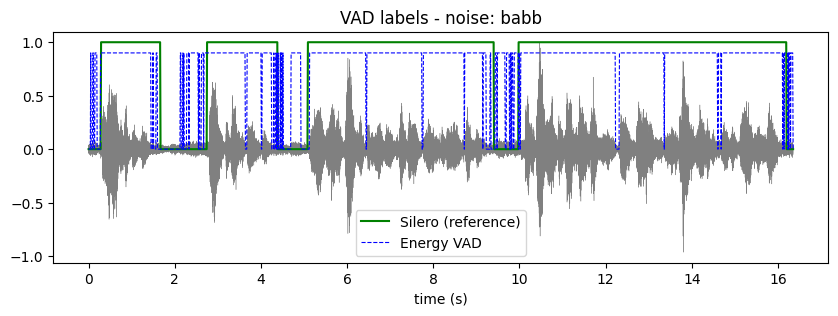

In [5]:
from silero_vad import load_silero_vad, get_speech_timestamps

# Frame-level reference labels from Silero VAD
silero = load_silero_vad()
labels = []
for i, w in enumerate(wavs):
    T = mels[i].shape[1]
    lab = np.zeros(T, np.float32)
    for s in get_speech_timestamps(w, silero, sampling_rate=SR):
        lab[s['start'] // HOP : s['end'] // HOP + 1] = 1
    labels.append(lab)

meta['speech_ratio'] = [l.mean() for l in labels]
print(meta.groupby('noise').speech_ratio.mean())

# Baseline: energy VAD (threshold = 10th percentile + delta dB)
def energy_vad(i, delta):
    e = energy[i].numpy()
    return (e > np.percentile(e, 10) + delta).astype(int)

y_tr = np.concatenate([labels[i] for i in tr_idx])
best = max(np.arange(0, 25, 1.0),
           key=lambda d: f1_score(y_tr, np.concatenate([energy_vad(i, d) for i in tr_idx])))
print('best delta (dB):', best)

# Plot waveform + labels for one test file
i = te_idx[0]
plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(wavs[i])) / SR, wavs[i].numpy() / wavs[i].abs().max().item(), lw=.3, c='gray')
plt.plot(np.arange(len(labels[i])) / 100, labels[i], 'g', label='Silero (reference)')
plt.plot(np.arange(len(labels[i])) / 100, energy_vad(i, best) * .9, 'b--', lw=.8, label='Energy VAD')
plt.title(f'VAD labels - noise: {meta.noise[i]}'); plt.xlabel('time (s)'); plt.legend(); plt.show()

*Figure 3. Waveform with Silero reference labels and Energy VAD output.*

### 5.3 CRNN model
I trained a convolutional recurrent neural network (CRNN). Three convolution blocks reduce only the frequency axis, so the time resolution of 10 ms is kept. A bidirectional GRU then looks at the context before and after each frame, and a linear layer gives a speech probability for every frame. The model was trained for 15 epochs on random 4-second crops with binary cross-entropy loss, and the loss went down to 0.041. At test time a median filter of 11 frames was applied to smooth the decisions.

epoch 1  loss 0.127
epoch 2  loss 0.080
epoch 3  loss 0.070
epoch 4  loss 0.059
epoch 5  loss 0.057
epoch 6  loss 0.052
epoch 7  loss 0.047
epoch 8  loss 0.053
epoch 9  loss 0.045
epoch 10  loss 0.048
epoch 11  loss 0.045
epoch 12  loss 0.043
epoch 13  loss 0.045
epoch 14  loss 0.041
epoch 15  loss 0.041
      F1_energy  F1_crnn  AUC_crnn
ALL       0.949    0.984     0.992
babb      0.940    0.982     0.993
musi      0.936    0.984     0.990
none      0.967    0.989     0.996
tele      0.951    0.982     0.990


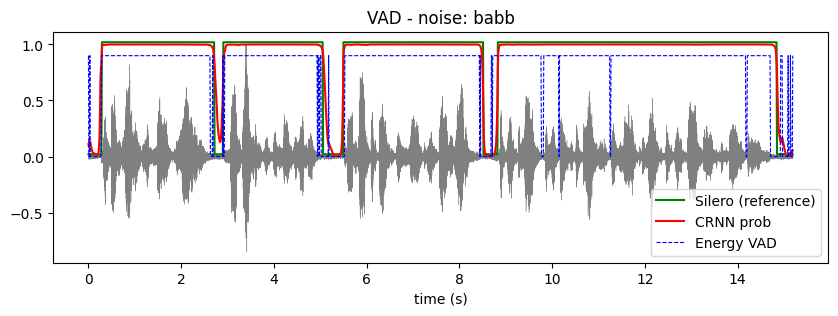

In [6]:
from sklearn.metrics import roc_auc_score
from scipy.ndimage import median_filter

VWIN = 400  # 4-second training crops

class VadDS(torch.utils.data.Dataset):
    def __init__(s, idx): s.idx = idx
    def __len__(s): return len(s.idx) * 4
    def __getitem__(s, k):
        i = s.idx[k % len(s.idx)]
        m, l = norm(mels[i]), torch.from_numpy(labels[i])
        if m.shape[1] < VWIN:
            m, l = F.pad(m, (0, VWIN - m.shape[1])), F.pad(l, (0, VWIN - len(l)))
        st = random.randint(0, m.shape[1] - VWIN)
        return m[:, st:st+VWIN].unsqueeze(0), l[st:st+VWIN]

class CRNN(nn.Module):
    def __init__(s):
        super().__init__()
        s.c = nn.Sequential(blk(1,16,(2,1)), blk(16,32,(2,1)), blk(32,64,(2,1)))  # pool freq only
        s.rnn = nn.GRU(64*8, 64, batch_first=True, bidirectional=True)
        s.out = nn.Linear(128, 1)
    def forward(s, x):
        h = s.c(x); B, C, Fq, T = h.shape
        h, _ = s.rnn(h.permute(0, 3, 1, 2).reshape(B, T, C*Fq))
        return s.out(h).squeeze(-1)

# Training
vad = CRNN().to(dev)
opt = torch.optim.AdamW(vad.parameters(), 1e-3)
dl = torch.utils.data.DataLoader(VadDS(tr_idx), batch_size=32, shuffle=True)
for ep in range(15):
    vad.train(); tot = 0
    for xb, lb in dl:
        xb, lb = aug(xb).to(dev), lb.to(dev)
        loss = F.binary_cross_entropy_with_logits(vad(xb), lb)
        opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item()
    print(f'epoch {ep+1}  loss {tot/len(dl):.3f}')

@torch.no_grad()
def crnn_prob(i):
    vad.eval()
    return torch.sigmoid(vad(norm(mels[i])[None, None].to(dev)))[0].cpu().numpy()

# Evaluation: frame-level F1 / AUC, overall and per noise type
rows = []
for i in te_idx:
    p = crnn_prob(i)
    rows.append(dict(noise=meta.noise[i], y=labels[i], p=p,
                     crnn=median_filter((p > .5).astype(int), 11),
                     en=energy_vad(i, best)))

def scores(rs):
    yy = np.concatenate([r['y'] for r in rs]); cat = lambda k: np.concatenate([r[k] for r in rs])
    return dict(F1_energy=f1_score(yy, cat('en')), F1_crnn=f1_score(yy, cat('crnn')),
                AUC_crnn=roc_auc_score(yy, cat('p')))

res_B = pd.DataFrame({'ALL': scores(rows),
                      **{n: scores([r for r in rows if r['noise'] == n]) for n in CLASSES}}).T
print(res_B.round(3))

# Plot one babble test file
i = te_idx[np.where(meta.noise.values[te_idx] == 'babb')[0][1]]
t = np.arange(len(labels[i])) / 100
plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(wavs[i])) / SR, wavs[i].numpy() / wavs[i].abs().max().item(), lw=.3, c='gray')
plt.plot(t, labels[i] + .02, 'g', label='Silero (reference)')
plt.plot(t, crnn_prob(i), 'r', label='CRNN prob')
plt.plot(t, energy_vad(i, best) * .9, 'b--', lw=.8, label='Energy VAD')
plt.title(f'VAD - noise: {meta.noise[i]}'); plt.xlabel('time (s)'); plt.legend(); plt.show()

**Table 3. Frame-level VAD results on the test set**

| Noise type | F1 (Energy VAD) | F1 (CRNN) | AUC (CRNN) |
|---|:---:|:---:|:---:|
| All | 0.949 | 0.984 | 0.992 |
| babb | 0.940 | 0.982 | 0.993 |
| musi | 0.936 | 0.984 | 0.990 |
| none | 0.967 | 0.989 | 0.996 |
| tele | 0.951 | 0.982 | 0.990 |

The CRNN was better than the energy baseline for every noise type. Its overall F1 was 0.984 and its AUC was 0.992. The energy method dropped the most with music (0.936) and babble (0.940), while the CRNN stayed around 0.98 for all noise types. Both methods worked best when there was no background noise.

The F1 of the energy baseline looks high, but this is partly because 86% of the frames are speech, so a method that says speech most of the time still gets a good F1. For this reason the AUC and the plots give a clearer view of the real difference. Figure 4 shows that the CRNN output almost matches the reference labels, including the start and end of each speech segment, while the energy VAD breaks in the middle of speech.

*Figure 4. Comparison of Silero reference, Energy VAD and CRNN on a babble test file.*

In [7]:
print('=== Part A: Event Detection ===')
print(pd.DataFrame(res_A, columns=['model', 'accuracy', 'macroF1']).round(3).to_string(index=False))
print('\n=== Part B: Voice Activity Detection ===')
print(res_B.round(3))

=== Part A: Event Detection ===
       model  accuracy  macroF1
      LogReg     0.785    0.785
     SVM-RBF     0.820    0.816
         kNN     0.598    0.572
RandomForest     0.766    0.752
   GradBoost     0.738    0.733
         MLP     0.770    0.767
 CNN log-Mel     0.949    0.948

=== Part B: Voice Activity Detection ===
      F1_energy  F1_crnn  AUC_crnn
ALL       0.949    0.984     0.992
babb      0.940    0.982     0.993
musi      0.936    0.984     0.990
none      0.967    0.989     0.996
tele      0.951    0.982     0.990


## 6. Conclusion
- **Event detection:** the CNN on log-Mel spectrograms reached 94.9% accuracy, compared with 82% for the best classical model (SVM on MFCC statistics). TV noise was the hardest class because it contains speech and music.
- **Voice activity detection:** the CRNN reached an F1 of 0.984 and an AUC of 0.992 and was better than the energy baseline under all noise types.
- Models that learn directly from the spectrogram and keep time information work much better in noisy rooms than simple hand-made features or energy thresholds.

### Limitations
- The VAD labels come from Silero VAD and not from human annotation, so the CRNN learns to copy Silero and cannot be better than it on this test.
- Only the 90-degree subset with two rooms was used, so results may change on the full dataset.